In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42

# On garde 2 variables numériques : ancienneté et prix mensuel
X2 = df[["tenure", "MonthlyCharges"]]

# Standardisation (moyenne 0, écart-type 1)
scaler2 = StandardScaler()
X2_scaled = scaler2.fit_transform(X2)
print(X2_scaled.mean(axis=0).round(3), X2_scaled.std(axis=0).round(3))

[-0. -0.] [1. 1.]


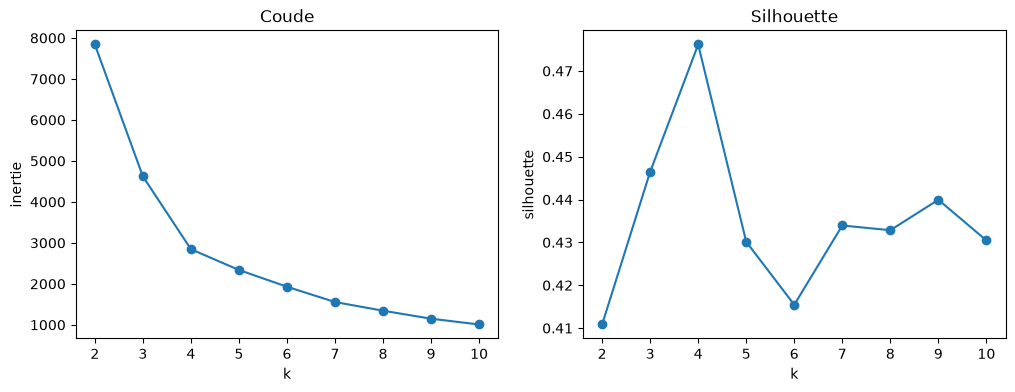

meilleur k (silhouette) : 4


In [9]:
# Coude (k de 1 à 10) et silhouette (k de 2 à 10, pas définie pour k = 1)
ks = range(2, 11)
inerties, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X2_scaled)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X2_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inerties, marker="o")
axes[0].set(title="Coude", xlabel="k", ylabel="inertie")
axes[1].plot(ks, silhouettes, marker="o")
axes[1].set(title="Silhouette", xlabel="k", ylabel="silhouette")
plt.show()
print("meilleur k (silhouette) :", ks[int(np.argmax(silhouettes))])